# Prétraitement :
De l'EDA à un jeu propre. **Point de départ : le fichier de l'EDA, corrigé** (correction ECMWF déjà appliquée par la binôme) : aucun téléchargement.
Ordre des étapes : fichier de départ → valeurs manquantes → conversions → qualité → correction 2022-2024 → outliers → transformation → variabilité → corrélations → échantillonnage → sauvegarde.

In [ ]:
import os, numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
BASE    = r"D:\M2\Data Mining\DM-Weather-framework\data"
OUT_DIR = f"{BASE}/processed"
PATH_EDA  = f"{OUT_DIR}/era5land_algeria_masked_x2.nc"             # fichier utilisé pour l'EDA (avant correction)
PATH_CORR = f"{OUT_DIR}/era5land_algeria_masked_x2_corrected.nc"   # même grille, APRÈS correction ECMWF (binôme)
VARS    = ["t2m","d2m","sp","u10","v10","slhf","sshf","ssr","str","e","ro","tp"]
ACC     = ["slhf","sshf","ssr","str","e","ro","tp"]                  # variables accumulées (touchées par l'anomalie)
HEAVY   = ["ro","tp","slhf","e"]                                     # queues lourdes (EDA)
FEATURES_SUP = ["d2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]   # liste de l'énoncé (SANS t2m)

## 1. Fichier de départ : EDA + correction
L'anomalie ECMWF (variables accumulées, sept. 2022 – fév. 2024) est dans le produit source : le fichier de l'EDA la contient. On part donc du fichier **corrigé** et on vérifie qu'il ne diffère du fichier de l'EDA que là où il le doit.

In [19]:
def load(path):
    d = xr.open_dataset(path).load()
    if "valid_time" in d.coords:
        d = d.rename({"valid_time": "time"})
    d["time"] = pd.DatetimeIndex(d.time.values).to_period("M").to_timestamp()
    return d.drop_vars(["number", "expver"], errors="ignore")

if not os.path.exists(PATH_CORR):
    raise FileNotFoundError(
        f"{PATH_CORR} introuvable. Deux solutions : (1) copier le fichier corrigé de ta binôme dans processed/ ; "
        "(2) lancer 03b_correction_ecmwf_optionnel.py, qui le recrée à partir du fichier de l'EDA.")
ds = load(PATH_CORR)        # point de départ : fichier de l'EDA + correction ECMWF (pas de nouveau téléchargement)

# Contrôle : le fichier corrigé ne doit différer du fichier de l'EDA que pour les variables accumulées (sept. 2022 - fév. 2024)
if os.path.exists(PATH_EDA):
    ds_eda = load(PATH_EDA)
    assert np.allclose(ds_eda.latitude, ds.latitude) and np.allclose(ds_eda.longitude, ds.longitude), "grilles différentes"
    rows = []
    for v in VARS:
        a, b = ds_eda[v].values, ds[v].reindex(time=ds_eda.time).values
        diff = ~np.isclose(a, b, rtol=1e-6, atol=0, equal_nan=True)
        mois = ds_eda.time.values[diff.any(axis=(1, 2))]
        rows.append({"var": v, "valeurs_modifiées": int(diff.sum()), "mois_modifiés": len(mois),
                     "du": str(mois.min())[:7] if len(mois) else "-", "au": str(mois.max())[:7] if len(mois) else "-"})
    print(pd.DataFrame(rows))
# Attendu : seules slhf, sshf, ssr, str, e, ro, tp sont modifiées, et uniquement entre 2022-09 et 2024-02.

     var  valeurs_modifiées  mois_modifiés       du       au
0    t2m                  0              0        -        -
1    d2m                  0              0        -        -
2     sp                  0              0        -        -
3    u10                  0              0        -        -
4    v10                  0              0        -        -
5   slhf              97650             18  2022-09  2024-02
6   sshf              97650             18  2022-09  2024-02
7    ssr              97650             18  2022-09  2024-02
8    str              97650             18  2022-09  2024-02
9      e              97650             18  2022-09  2024-02
10    ro              67585             18  2022-09  2024-02
11    tp              97650             18  2022-09  2024-02


## 2. Valeurs manquantes
Cours : > 50 % manquant → suppression ; < 5 % → imputation. Ici chaque point est à 0 % ou 100 % → on **supprime** les points vides, sans imputation.

In [20]:
n_time = ds.sizes["time"]
all_nan = ds["t2m"].isnull().all("time")
n_valid = int((~all_nan).sum())
print(f"{all_nan.size} points de grille | entièrement NaN : {int(all_nan.sum())} "
      f"(hors pays + 5 points du littoral nord) | exploitables : {n_valid} | mois : {n_time}")

# Règle du cours (chap. 4) : > 50 % de valeurs manquantes -> suppression ; < 5 % -> imputation.
miss_pct = ds[VARS].to_array(dim="v").isnull().any("v").mean("time") * 100      # % de mois manquants par point
print("points à 100 % manquants :", int((miss_pct == 100).sum()),
      "| à 0 % :", int((miss_pct == 0).sum()),
      "| entre les deux :", int(((miss_pct > 0) & (miss_pct < 100)).sum()))
# Attendu : 4143 / 5425 / 0 -> aucun cas intermédiaire : on SUPPRIME les points à 100 %, aucune imputation.

9568 points de grille | entièrement NaN : 4143 (hors pays + 5 points du littoral nord) | exploitables : 5425 | mois : 140
points à 100 % manquants : 4143 | à 0 % : 5425 | entre les deux : 0


## 3. DataFrame, conversions, mois
Suppression des `NaN`, Kelvin → °C, ajout du mois.

In [21]:
df = ds[VARS].to_dataframe().reset_index().dropna()
df = df[["time", "latitude", "longitude"] + VARS]
assert len(df) == n_valid * n_time, (len(df), n_valid * n_time)        # 5425 x 140 = 759 500
print("NaN restants :", int(df[VARS].isna().sum().sum()))
df[["t2m", "d2m"]] -= 273.15                                           # Kelvin -> °C
df["month"] = df["time"].dt.month
df = df.sort_values(["time", "latitude", "longitude"]).reset_index(drop=True)

NaN restants : 0


## 4. Contrôles de qualité
Mesures de qualité du cours : complétude, cohérence, exactitude. Aucune anomalie attendue.

In [22]:
def quality_checks(d):
    dates = pd.DatetimeIndex(sorted(d["time"].unique()))
    attendues = pd.date_range(dates.min(), dates.max(), freq="MS")
    return {
        "valeurs_infinies": int(np.isinf(d[VARS]).sum().sum()),
        "doublons": int(d.duplicated(["time", "latitude", "longitude"]).sum()),
        "t2m<d2m": int((d["t2m"] < d["d2m"]).sum()),
        "sp<=0": int((d["sp"] <= 0).sum()),
        "tp<0": int((d["tp"] < 0).sum()),
        "ro<0": int((d["ro"] < 0).sum()),
        "dates_manquantes": len(attendues.difference(dates)),
        "variables_constantes": [c for c in VARS if d[c].nunique() <= 1],
    }
qc = quality_checks(df)
print(qc)
assert all(v in (0, []) for v in qc.values()), "anomalie de qualité : voir qc"

# Lecture selon les mesures de qualité du cours (chap. 4)
qualite = pd.DataFrame([
    ("Complétude",  "NaN restants après suppression des points vides", int(df[VARS].isna().sum().sum())),
    ("Complétude",  "mois manquants dans la série",                    qc["dates_manquantes"]),
    ("Cohérence",   "doublons (temps, latitude, longitude)",           qc["doublons"]),
    ("Cohérence",   "t2m < d2m",                                       qc["t2m<d2m"]),
    ("Exactitude",  "sp <= 0, tp < 0 ou ro < 0",                       qc["sp<=0"] + qc["tp<0"] + qc["ro<0"]),
    ("Exactitude",  "valeurs infinies",                                qc["valeurs_infinies"]),
], columns=["Mesure", "Contrôle", "Anomalies"])
print(qualite)
# Autres mesures : Exactitude/Cohérence temporelle -> cellule 4 (correction ECMWF) ; Actualité -> données jusqu'à
# août 2026 ; Crédibilité -> réanalyse ECMWF/C3S ; Interprétabilité -> conversions d'unités (K -> °C).

{'valeurs_infinies': 0, 'doublons': 0, 't2m<d2m': 0, 'sp<=0': 0, 'tp<0': 0, 'ro<0': 0, 'dates_manquantes': 0, 'variables_constantes': []}
       Mesure                                         Contrôle  Anomalies
0  Complétude  NaN restants après suppression des points vides          0
1  Complétude                     mois manquants dans la série          0
2   Cohérence            doublons (temps, latitude, longitude)          0
3   Cohérence                                        t2m < d2m          0
4  Exactitude                        sp <= 0, tp < 0 ou ro < 0          0
5  Exactitude                                 valeurs infinies          0


## 5. Contrôle de la correction ECMWF
Le z-score mensuel et la figure doivent montrer que la rupture 2022-2024 a disparu.

**Vérification de la correction des variables accumulées:**

Une correction a été effectuée sur les variables accumulées d'ERA5-Land pour la période allant de septembre 2022 à février 2024. Les sept variables concernées ont été retéléchargées depuis le CDS, puis intégrées aux fichiers annuels en conservant les variables instantanées.

Afin d'examiner la cohérence des données après correction, deux vérifications complémentaires ont été réalisées :

- **Vérification statistique :** calcul d'un Z-score robuste à partir des moyennes spatiales mensuelles, en comparant chaque observation à la distribution historique du même mois calendaire. Cette analyse permet de repérer les valeurs temporellement atypiques.
- **Vérification visuelle :** représentation de l'évolution temporelle des moyennes spatiales des variables, avec mise en évidence de la période concernée par la correction.

Ces vérifications permettent d'examiner la cohérence temporelle des données corrigées et de repérer d'éventuelles ruptures ou valeurs inhabituelles. Elles ne constituent toutefois pas une comparaison directe entre les anciennes et les nouvelles données.

mois avec |z|>3 : {'slhf': 10, 'sshf': 6, 'ssr': 9, 'str': 6, 'e': 10, 'ro': 13, 'tp': 11}


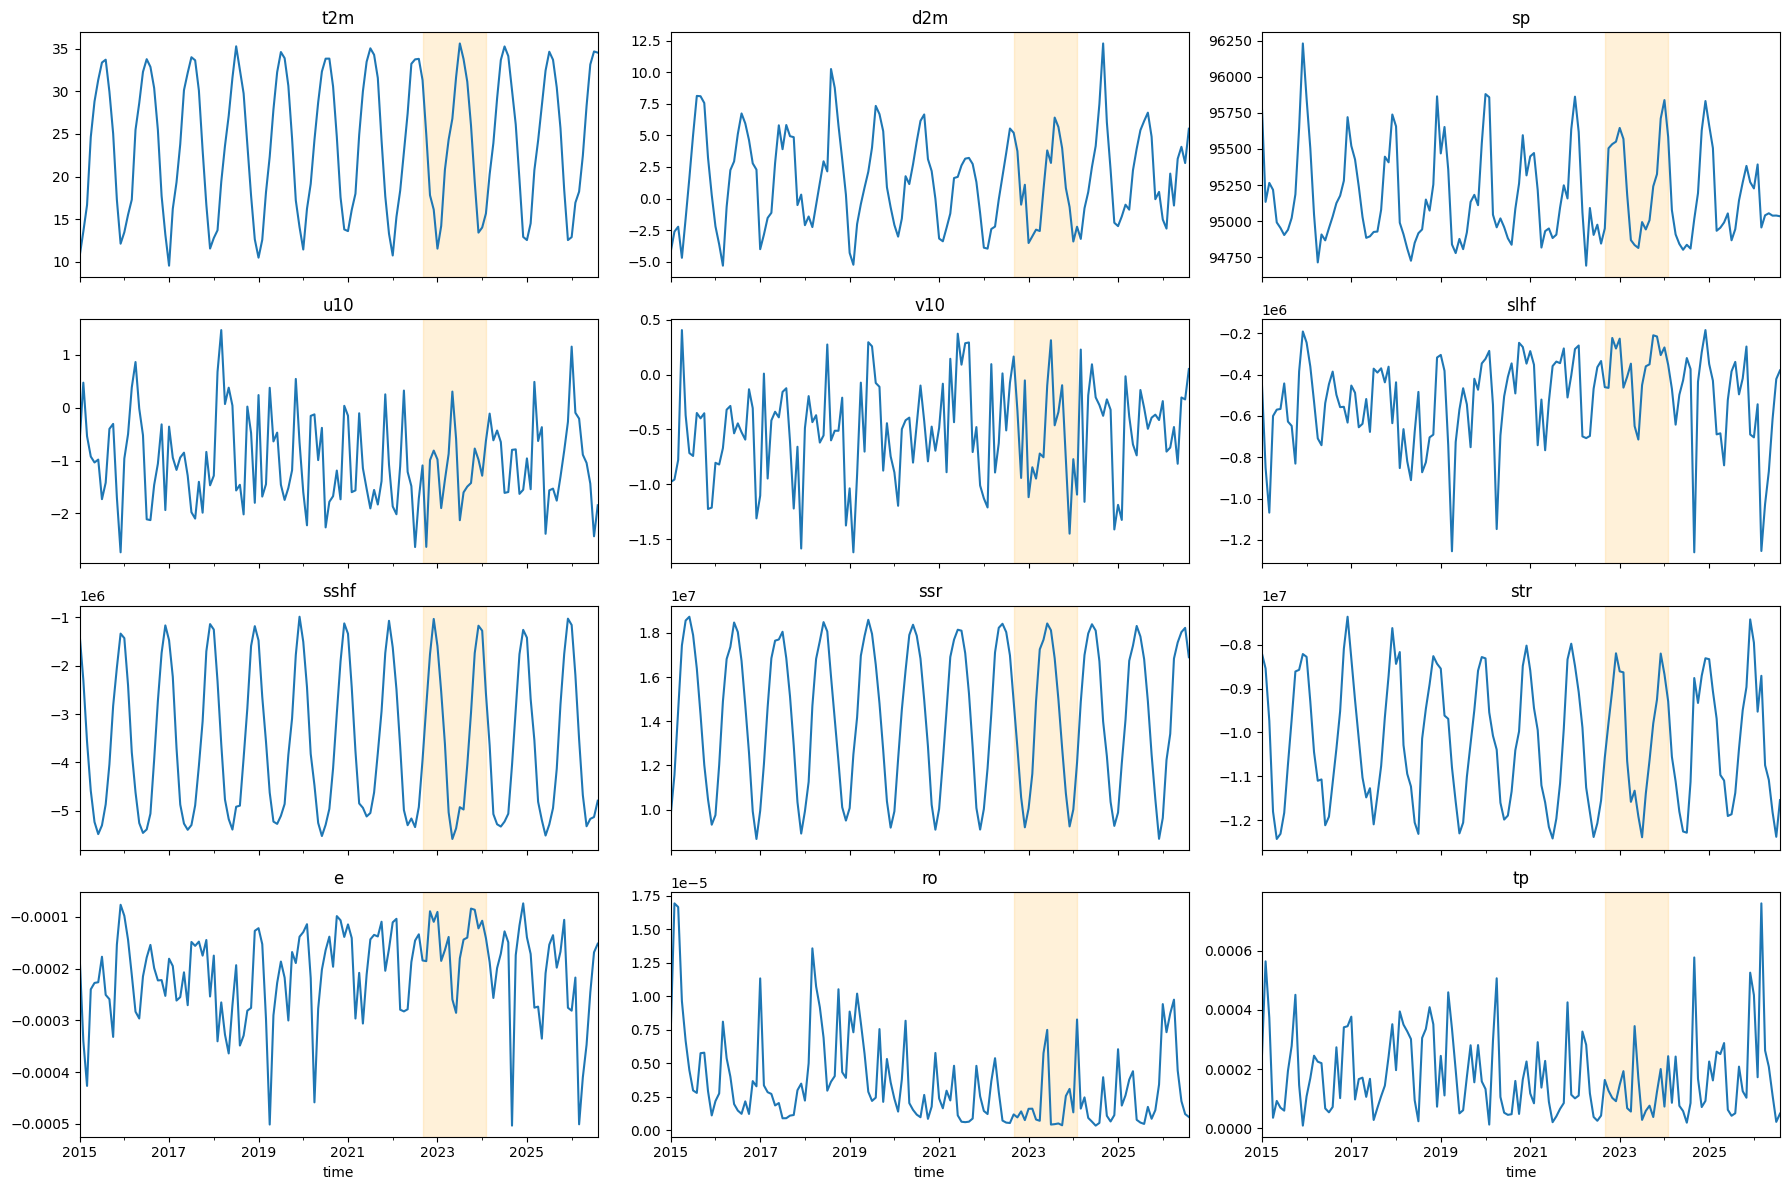

In [23]:
def monthly_z(d, cols):
    m = d.groupby("time")[cols].mean()
    med = m.groupby(m.index.month).transform("median")
    mad = m.groupby(m.index.month).transform(lambda x: (x - x.median()).abs().median()) * 1.4826
    return (m - med) / mad
z = monthly_z(df, ACC)
print("mois avec |z|>3 :", z.abs().gt(3).sum().to_dict())        # doit être ~0 après correction

os.makedirs("figures", exist_ok=True)
mo = df.groupby("time")[VARS].mean()
fig, axes = plt.subplots(4, 3, figsize=(18, 12), sharex=True)
for ax, v in zip(axes.ravel(), VARS):
    mo[v].plot(ax=ax, title=v); ax.axvspan("2022-09-01", "2024-02-28", color="orange", alpha=0.15)
plt.tight_layout(); fig.savefig("figures/f20_variation_mensuelle_corrigee.png", dpi=200)

## 5. Séparation des données Train/Test

Avant d'effectuer les transformations nécessaires à la modélisation, nous devons séparer les données en deux ensembles : **Train** et **Test**.

Cette séparation permet d'éviter le phénomène de *Data Leakage* (fuite de données), qui se produit lorsque des informations provenant de l'ensemble de test sont utilisées pendant la préparation ou l'entraînement du modèle.

Dans notre projet, les données sont des observations météorologiques mensuelles. Il est donc nécessaire d'utiliser une **séparation chronologique** plutôt qu'une séparation aléatoire.

- **Train set :** contient les observations des périodes les plus anciennes. Il est utilisé pour apprendre les paramètres des transformations et entraîner les modèles.
- **Test set :** contient les observations des périodes les plus récentes. Il est conservé à part afin d'évaluer les performances des modèles sur des données qu'ils n'ont pas utilisées pendant leur apprentissage.


**Pourquoi mars 2024 est absent ?**:

C'est volontaire. En effet :
- Février 2024 : les variables d'entrée correspondent à février et la cible à mars. L'observation reste dans Train.
- Mars 2024 : les variables d'entrée correspondent à mars, mais la cible correspond à avril. Cette observation est exclue pour éviter que Train utilise une cible située dans la période Test.
- Avril 2024 : l'observation appartient à Test.
C'est une précaution pour éviter les fuites de données (data leakage) entre les deux ensembles

In [24]:
# 1. Création de la cible : température du mois suivant

df = df.sort_values(
    ["latitude", "longitude", "time"]
).copy()

df["t2m_next"] = (
    df.groupby(["latitude", "longitude"])["t2m"].shift(-1)
)

df["target_time"] = (
    df.groupby(["latitude", "longitude"])["time"].shift(-1)
)

# Vérification de la continuité mensuelle
df = df.dropna(subset=["t2m_next", "target_time"])

assert (
    df["target_time"] == df["time"] + pd.offsets.MonthBegin(1)
).all()


# 2. Séparation : 80/20

dates = sorted(df["time"].unique())

split_idx = int(len(dates) * 0.8)
date_limite = dates[split_idx]

# mars 2024 est absent
train = df[
    (df["time"] < date_limite) &
    (df["target_time"] < date_limite)
].copy()

test = df[
    df["time"] >= date_limite
].copy()


# 3. Vérification

print("Date limite :", date_limite)

print("Train :", train.shape)
print("Test :", test.shape)

print("Période Train :", train["time"].min(), "->", train["time"].max())
print("Période Test :", test["time"].min(), "->", test["time"].max())

Date limite : 2024-04-01 00:00:00
Train : (596750, 18)
Test : (151900, 18)
Période Train : 2015-01-01 00:00:00 -> 2024-02-01 00:00:00
Période Test : 2024-04-01 00:00:00 -> 2026-07-01 00:00:00


## 6. Valeurs aberrantes
IQR global, IQR par point et par mois, coïncidence des extrêmes entre variables (inspection ordinateur + humain). **Décision : on conserve les extrêmes** (plausibles physiquement).

| Variable extrême | Variable à comparer | Relation physique recherchée |
|---|---|---|
| `tp` | `ro` | Précipitations importantes pouvant entraîner un ruissellement |
| `tp` | `e` | Précipitations et évaporation, en tenant compte des conditions climatiques |
| `slhf` | `e` | Cohérence entre flux de chaleur latente et évaporation |
| `slhf` | `t2m`, `d2m` | Cohérence avec les conditions thermiques et l'humidité atmosphérique |

In [25]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

def outlier_flags(d, cols):
    out = {}
    for c in cols:
        lo, hi = iqr_bounds(d[c]); out[c] = (d[c] < lo) | (d[c] > hi)
    return pd.DataFrame(out)

def temporal_flags(d, cols):                                # IQR par (latitude, longitude, mois)
    g, out = d.groupby(["latitude", "longitude", "month"]), {}
    for c in cols:
        q1, q3 = g[c].transform("quantile", .25), g[c].transform("quantile", .75); i = q3 - q1
        out[c] = (d[c] < q1 - 1.5 * i) | (d[c] > q3 + 1.5 * i)
    return pd.DataFrame(out)

def coincidence(a, b, na, nb):
    both = int((a & b).sum())
    return {f"{na} avec {nb} (%)": round(100 * both / max(int(a.sum()), 1), 2),
            f"{nb} avec {na} (%)": round(100 * both / max(int(b.sum()), 1), 2)}

flags = outlier_flags(df, VARS)
rapport = pd.DataFrame({"skew": skew(df[VARS]), "kurtosis": kurtosis(df[VARS]),
                        "n_outliers": flags.sum(), "%": flags.mean() * 100}, index=VARS).round(3)
print(rapport)

tflags = temporal_flags(df, HEAVY)
print(pd.DataFrame({"global": flags[HEAVY].sum(), "par_point_et_mois": tflags.sum(),
                    "les_deux": (flags[HEAVY] & tflags).sum()}))
for a, b in [("tp", "ro"), ("tp", "e"), ("e", "slhf")]:
    print(coincidence(flags[a], flags[b], a, b))

# Cours (chap. 4) : inspection « ordinateur + humain » (blocs ci-dessus), puis transformation (cellule 8) et modèles robustes.
# Décision : on CONSERVE les extrêmes (valeurs physiquement plausibles, fortement liées entre variables).
# On ne supprimerait que des violations physiques, et le contrôle 3 n'en trouve aucune.
df_clean = df.copy()

        skew  kurtosis  n_outliers       %
t2m   -0.106    -1.158           0   0.000
d2m    0.295     0.324        8782   1.165
sp    -0.841     0.473       13694   1.816
u10    0.079     0.156        5541   0.735
v10   -0.242     0.043        7961   1.056
slhf  -3.977    19.234      126958  16.836
sshf  -0.387     0.381        6827   0.905
ssr   -0.113    -0.810           0   0.000
str    0.360    -0.462         554   0.073
e     -3.977    19.236      126957  16.836
ro    35.089  2438.859      123087  16.323
tp     5.626    45.093      114760  15.219
      global  par_point_et_mois  les_deux
ro    123087              76550     31401
tp    114760              73475     29700
slhf  126958              71780     26429
e     126957              71785     26433
{'tp avec ro (%)': 94.14, 'ro avec tp (%)': 87.78}
{'tp avec e (%)': 91.93, 'e avec tp (%)': 83.1}
{'e avec slhf (%)': 100.0, 'slhf avec e (%)': 100.0}


## 7. Transformation des queues lourdes
Cours : log, racine. Comparaison de la skewness, puis log signé à échelle apprise sur le train (log1p direct est sans effet sur des valeurs en mètres).

In [26]:
# log1p(x) direct serait quasi sans effet (|x| ~ 1e-7 à 1e-2) : on divise d'abord par une échelle typique.
from sklearn.base import BaseEstimator, TransformerMixin

def compare_transforms(d, cols):       # diagnostic (échelle estimée sur tout le jeu, jamais utilisé pour les modèles)
    rows = []
    for c in cols:
        x = d[c].astype("float64");
        a = np.abs(x);
        s = np.median(a) or a.mean()
        rows.append({"var": c, "brut": skew(x),
                     "log1p_direct": skew(np.sign(x) * np.log1p(a)),
                     "racine": skew(np.sign(x) * np.sqrt(a)),
                     "log_signe_echelle": skew(np.sign(x) * np.log1p(a / s))})
    return pd.DataFrame(rows).set_index("var").round(2)
print(compare_transforms(train, HEAVY))     # on compare train

class SignedLog1p(BaseEstimator, TransformerMixin):
    def __init__(self, cols): self.cols = cols
    def fit(self, X, y=None):
        self.scale_ = {c: (np.median(np.abs(X[c])) or np.mean(np.abs(X[c]))) for c in self.cols}
        return self
    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            X[c] = np.sign(X[c]) * np.log1p(np.abs(X[c]) / self.scale_[c])
        return X

# À utiliser APRÈS le découpage chronologique (feature engineering) :
slog = SignedLog1p(HEAVY).fit(train)
train_t, test_t = slog.transform(train), slog.transform(test)
# puis StandardScaler (ou RobustScaler) ajusté sur train_t uniquement.

# pour le insupervise on doit sauvgrder tt la datset pas separe :
# Transformation de la dataset complète pour l'apprentissage non supervisé
df_unsup_preprocessed = slog.transform(df_clean)


       brut  log1p_direct  racine  log_signe_echelle
var                                                 
ro    35.63         35.57    8.03               1.76
tp     5.83          5.82    2.55               1.23
slhf  -4.03         -0.92   -2.39              -1.72
e     -4.03         -4.02   -2.39              -1.72


## 8. Faible variabilité
CV et variance min-max (< 0,01), **avant et après** transformation. Aucune variable supprimée sur ce seul critère.

In [ ]:
# Analyse de la variabilité sur Train uniquement

cv = (
    train[VARS].std() /
    train[VARS].mean().abs() * 100
)

vmm = (
    (train[VARS] - train[VARS].min()) /
    (train[VARS].max() - train[VARS].min())
).var()

var_tab = pd.DataFrame({
    "CV_%": cv,
    "var_minmax": vmm,
    "std_temporel": train.groupby("time")[VARS].mean().std(),
    "std_spatial": train.groupby(
        ["latitude", "longitude"]
    )[VARS].mean().std()
})

print(var_tab.sort_values("CV_%").round(4))
print("CV < 5 % :", list(var_tab.index[var_tab["CV_%"] < 5]))
print(
    "variance min-max < 0.01 :",
    list(var_tab.index[var_tab["var_minmax"] < 0.01])
)

# La faible variance de ro/tp/e/slhf vient-elle des extrêmes ? On la recalcule APRÈS la transformation log.
# Variance après transformation sur Train
vmm_t = (
    (train_t[VARS] - train_t[VARS].min()) /
    (train_t[VARS].max() - train_t[VARS].min())
).var()
print(pd.DataFrame({"var_minmax_avant": vmm[HEAVY], "var_minmax_apres": vmm_t[HEAVY]}).round(4))
# Décision : aucune variable supprimée sur ce seul critère ; sp est testée avec et sans (voir 7).

          CV_%  var_minmax  std_temporel   std_spatial
sp      3.5274      0.0201  3.360584e+02  3.339188e+03
str    19.3377      0.0282  1.439908e+06  1.238977e+06
ssr    25.8160      0.0320  3.265170e+06  1.503173e+06
t2m    37.4106      0.0465  8.024500e+00  3.400800e+00
sshf   53.3226      0.0087  1.524536e+06  9.157812e+05
u10   155.6410      0.0128  8.345000e-01  9.253000e-01
slhf  196.2949      0.0073  2.076644e+05  8.446026e+05
e     196.2970      0.0073  1.000000e-04  3.000000e-04
v10   197.7044      0.0172  4.502000e-01  6.406000e-01
tp    279.3952      0.0018  1.000000e-04  3.000000e-04
d2m   373.2649      0.0154  3.624000e+00  2.815100e+00
ro    939.7119      0.0001  0.000000e+00  0.000000e+00
CV < 5 % : ['sp']
variance min-max < 0.01 : ['slhf', 'sshf', 'e', 'ro', 'tp']
      var_minmax_avant  var_minmax_apres
ro              0.0001            0.0212
tp              0.0018            0.0397
slhf            0.0073            0.0337
e               0.0073            0.0337


## 9. Corrélations (Spearman)
Règle du cours : > 90 %. Jeux de variables à comparer au chapitre 3 : `complet`, `reduit`, `reduit_sans_sp`, `strict_cours`.

In [ ]:
corr = train[VARS].corr(method="spearman")
paires = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print(paires[paires.abs() > 0.9].sort_values(key=abs, ascending=False).round(3))

DROP = ["e", "ro"]                       # e = doublon exact de slhf ; ro corrélée à tp (0.98)
FEATURE_SETS = {
    "complet":        FEATURES_SUP,
    "reduit":         [v for v in FEATURES_SUP if v not in DROP],
    "reduit_sans_sp": [v for v in FEATURES_SUP if v not in DROP + ["sp"]],
}
# Règle stricte du cours (corrélation > 90 %) : ssr-sshf (|rho| = 0.95) est aussi concernée -> on retire sshf (ssr : rho 0.71 avec la cible).
FEATURE_SETS["strict_cours"] = [v for v in FEATURES_SUP if v not in DROP + ["sshf"]]
for k, v in FEATURE_SETS.items():
    print(k, len(v), v)

slhf  e      1.000
ro    tp     0.980
sshf  ssr   -0.956
dtype: float64
complet 11 ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']
reduit 9 ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp']
reduit_sans_sp 8 ['d2m', 'slhf', 'ssr', 'str', 'sshf', 'u10', 'v10', 'tp']
strict_cours 8 ['d2m', 'slhf', 'ssr', 'str', 'u10', 'v10', 'sp', 'tp']


## 10. Réduction de numérosité
Échantillonnage stratifié / systématique (utile pour SVM et KNN).

In [ ]:
def stratified_sample(d, labels, frac, seed=42):      # conserve les proportions de classes (classification)
    return d.groupby(labels, group_keys=False).sample(frac=frac, random_state=seed)
def systematic_sample(d, k):                          # un enregistrement sur k
    return d.iloc[::k]
# Exemple (après construction de la cible et découpage) : train_small = stratified_sample(train, train["classe"], 0.1)

## 11. Sauvegarde
Jeu propre, entrée du feature engineering (cible, découpage chronologique, scaler, sin/cos du mois).

In [27]:
# Dossier de sauvegarde des données transformées
OUT_DIR_TRANSFORMED = os.path.join(OUT_DIR, "transformed")

os.makedirs(OUT_DIR_TRANSFORMED, exist_ok=True)

# Sauvegarde de Train transformé
train_t.to_parquet(
    f"{OUT_DIR_TRANSFORMED}/train_transformed.parquet",
    index=False
)

# Sauvegarde de Test transformé
test_t.to_parquet(
    f"{OUT_DIR_TRANSFORMED}/test_transformed.parquet",
    index=False
)

# Sauvegarde du dataset complet pour l'apprentissage non supervisé
df_unsup_preprocessed.to_parquet(
    f"{OUT_DIR_TRANSFORMED}/dataset_unsupervised.parquet",
    index=False
)

# Affichage des informations
print("========== SAUVEGARDE DES DATASETS ==========")

print("\nDataset Train :")
print("Nombre de lignes :", train_t.shape[0])
print("Nombre de colonnes :", train_t.shape[1])
print("Dimensions :", train_t.shape)
print("Période :", train_t["time"].min(), "->", train_t["time"].max())

print("\nDataset Test :")
print("Nombre de lignes :", test_t.shape[0])
print("Nombre de colonnes :", test_t.shape[1])
print("Dimensions :", test_t.shape)
print("Période :", test_t["time"].min(), "->", test_t["time"].max())

print("\nNombre total de lignes :", len(train_t) + len(test_t))
print("Dossier de sauvegarde :", OUT_DIR)

========== SAUVEGARDE DES DATASETS ==========

Dataset Train :
Nombre de lignes : 596750
Nombre de colonnes : 18
Dimensions : (596750, 18)
Période : 2015-01-01 00:00:00 -> 2024-02-01 00:00:00

Dataset Test :
Nombre de lignes : 151900
Nombre de colonnes : 18
Dimensions : (151900, 18)
Période : 2024-04-01 00:00:00 -> 2026-07-01 00:00:00

Nombre total de lignes : 748650
Dossier de sauvegarde : /content/drive/MyDrive/DataMining_Climat/processed
